# Compare the position effect on the validation plates with the screen

This notebook puts the validation plates next to the screen, with the same measurements on both, to show why the plate-position correction removed most of the position effect in the screen and only part of it on the validation plates.
It changes no data: it reads the well medians and the fit of this step (`1.fit_position_correction.ipynb`) and of the screen (`4.image_based_profiling/3a.position_correction`).

1. **Variance by principal component, split into position and heart status.** The principal components of the well profiles, with the part of each component that plate position (row plus column) explains in red and the part that the heart status of the cells (healthy against failing) explains in blue, before and after the correction.
2. **Survival of the healthy against failing difference.** The length of the difference between the healthy and the failing DMSO profile on every plate, before and after the correction.
3. **What the tilt estimates, and how well.** The size of each row and column term of the tilt on the validation plates, with its uncertainty from leaving each plate out in turn, and the position variation of every feature before and after the correction.
4. **Compound placement in the screen.** Whether the position of a compound on the screen platemaps is independent of the compound.

**Input**

- `well_medians.parquet` and `position_correction_fit.npz` of this folder (validation plates)
- `../../../4.image_based_profiling/3a.position_correction/well_medians.parquet` and `position_correction_fit.npz` (screen; the cache of the well medians is git-ignored, so run the screen's fit notebook first when it is missing)
- `../../../metadata/updated_platemaps/` (screen platemaps)

**Output**: tables in `results/` and figures in `figures/compare_to_screen/`.

## Import libraries

In [1]:
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, spearmanr

sys.path.append("../../../utils")
import position_correction_effect_utils as pce
import position_correction_utils as pcu
import validation_position_utils as vpu

## Set paths and parameters

In [2]:
figure_dir = pathlib.Path("figures") / "compare_to_screen"
figure_dir.mkdir(parents=True, exist_ok=True)
results_dir = pathlib.Path("results")
results_dir.mkdir(exist_ok=True)

screen_dir = pathlib.Path("../../../4.image_based_profiling/3a.position_correction")
platemap_dir = pathlib.Path("../../../metadata/updated_platemaps")
for path in (
    pathlib.Path("well_medians.parquet"),
    pathlib.Path("position_correction_fit.npz"),
    screen_dir / "well_medians.parquet",
    screen_dir / "position_correction_fit.npz",
):
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run the fit notebooks of the screen and of this step first.")

min_cells = 50  # minimum cells for a well to be used (as in the screen)
n_components = 20  # principal components to show
seed = 0

# the two data sets, with the label of the healthy cells in each
datasets = {
    "Screen": {
        "medians": pd.read_parquet(screen_dir / "well_medians.parquet"),
        "fit": pcu.load_fit(screen_dir / "position_correction_fit.npz"),
        "healthy": "healthy",
    },
    "Validation": {
        "medians": pd.read_parquet("well_medians.parquet"),
        "fit": pcu.load_fit("position_correction_fit.npz"),
        "healthy": vpu.HEALTHY_CELL_TYPE,
    },
}
colors = {"position": "#d62728", "status": "#1f77b4", "total": "#bdbdbd"}
for name, data in datasets.items():
    # the screen analysis of the principal components uses every well, whatever its number of cells
    data["all_wells"] = data["medians"].reset_index(drop=True)
    data["medians"] = data["medians"][data["medians"]["n"] >= min_cells].reset_index(drop=True)
    print(name, "| wells:", len(data["medians"]), "| plates:", data["medians"]["plate"].nunique(), "| features:", len(data["fit"]["features"]))

Screen | wells: 1842 | plates: 44 | features: 2446
Validation | wells: 300 | plates: 5 | features: 2453


## 1. Variance by principal component: position and heart status

We fit the principal components on the uncorrected wells (controls included), as in `3.effect_on_feature_space.ipynb`, and project the corrected wells on the same components.
For every component:

- the **grey bar** is the variance of the wells on the component, as a percentage of the total variance of the uncorrected wells;
- the **red bar** is the part of it that plate position explains, from an additive row plus column regression (adjusted R squared times the variance);
- the **blue bar** is the part that heart status explains (healthy against failing cells, R squared times the variance).

Heart status and position are partly confounded.
On the screen, the healthy wells are all in row B and the failing control wells in row E, so the blue bar before the correction also contains position.
On the validation plates the two cell types have the same number of wells in each of the six rows, so row does not confound heart status, but they sit in different blocks of columns (failing in columns 2, 4, and 10, healthy in 3, 9, and 11), so column does.
The validation fit uses the DMSO wells of both cell types, and what remains in the blue bar afterwards is the difference between healthy and failing cells that the position terms do not explain.
The red bar after the correction is the position variation that the fit leaves in the wells that it was fit on, which a fit on its own data always favors.
The position variation that the correction leaves in wells of a plate that it never saw is in section 3.

In [3]:
def adjusted_r_squared(scores, design):
    """Adjusted R squared of every column of ``scores`` on ``design`` (which has its own intercept)."""
    n_wells, n_terms = design.shape
    coefficients = np.linalg.lstsq(design, scores, rcond=None)[0]
    residual = ((scores - design @ coefficients) ** 2).sum(axis=0)
    total = ((scores - scores.mean(axis=0)) ** 2).sum(axis=0)
    return 1 - (residual / total) * (n_wells - 1) / (n_wells - n_terms)


def partition_variance(medians, fit, healthy_label):
    """Split the variance of the principal components into position and heart status."""
    features = list(fit["features"])
    raw = medians[features].to_numpy(float)
    corrected = pce.correct_well_medians(medians, fit)[features].to_numpy(float)
    pca = pce.fit_pca(raw, n_components, seed)
    total_variance = pca.explained_variance_[0] / pca.explained_variance_ratio_[0]
    scores = {"before": pca.transform(raw), "after": pca.transform(corrected)}
    rows, cols = pcu.well_index(medians["well"])
    design = pcu.design_matrix(rows, cols)
    status = (medians["cell_type"] == healthy_label).to_numpy(float)
    records = []
    for stage, values in scores.items():
        variance = values.var(axis=0, ddof=1)
        position = np.clip(adjusted_r_squared(values, design), 0, None)
        status_r2 = np.array([np.corrcoef(values[:, k], status)[0, 1] ** 2 for k in range(n_components)])
        for k in range(n_components):
            records.append(
                {
                    "stage": stage,
                    "component": f"PC{k + 1}",
                    "variance_pct_of_total": 100 * variance[k] / total_variance,
                    "position_pct_of_total": 100 * variance[k] * position[k] / total_variance,
                    "status_pct_of_total": 100 * variance[k] * status_r2[k] / total_variance,
                    "position_r2": position[k],
                    "status_r2": status_r2[k],
                }
            )
    return pd.DataFrame(records)


# the principal components of the screen are fit on all of its wells, as in its own analysis; the validation plates have 300 wells with at least 50 cells
partitions = {
    name: partition_variance(data["all_wells"] if name == "Screen" else data["medians"], data["fit"], data["healthy"])
    for name, data in datasets.items()
}
pd.concat(partitions, names=["dataset"]).reset_index(level=0).to_csv(results_dir / "scree_position_and_heart_status.csv", index=False)
for name, table in partitions.items():
    print(f"\n{name}: share of the variance of the first {n_components} components, by stage")
    print(
        table.groupby("stage")[["variance_pct_of_total", "position_pct_of_total", "status_pct_of_total"]]
        .sum()
        .round(1)
        .to_string()
    )


Screen: share of the variance of the first 20 components, by stage
        variance_pct_of_total  position_pct_of_total  status_pct_of_total
stage                                                                    
after                    79.8                    1.4                  0.7
before                   85.7                    6.8                  1.3

Validation: share of the variance of the first 20 components, by stage
        variance_pct_of_total  position_pct_of_total  status_pct_of_total
stage                                                                    
after                    63.5                   12.6                  4.1
before                   94.6                   43.2                  4.1


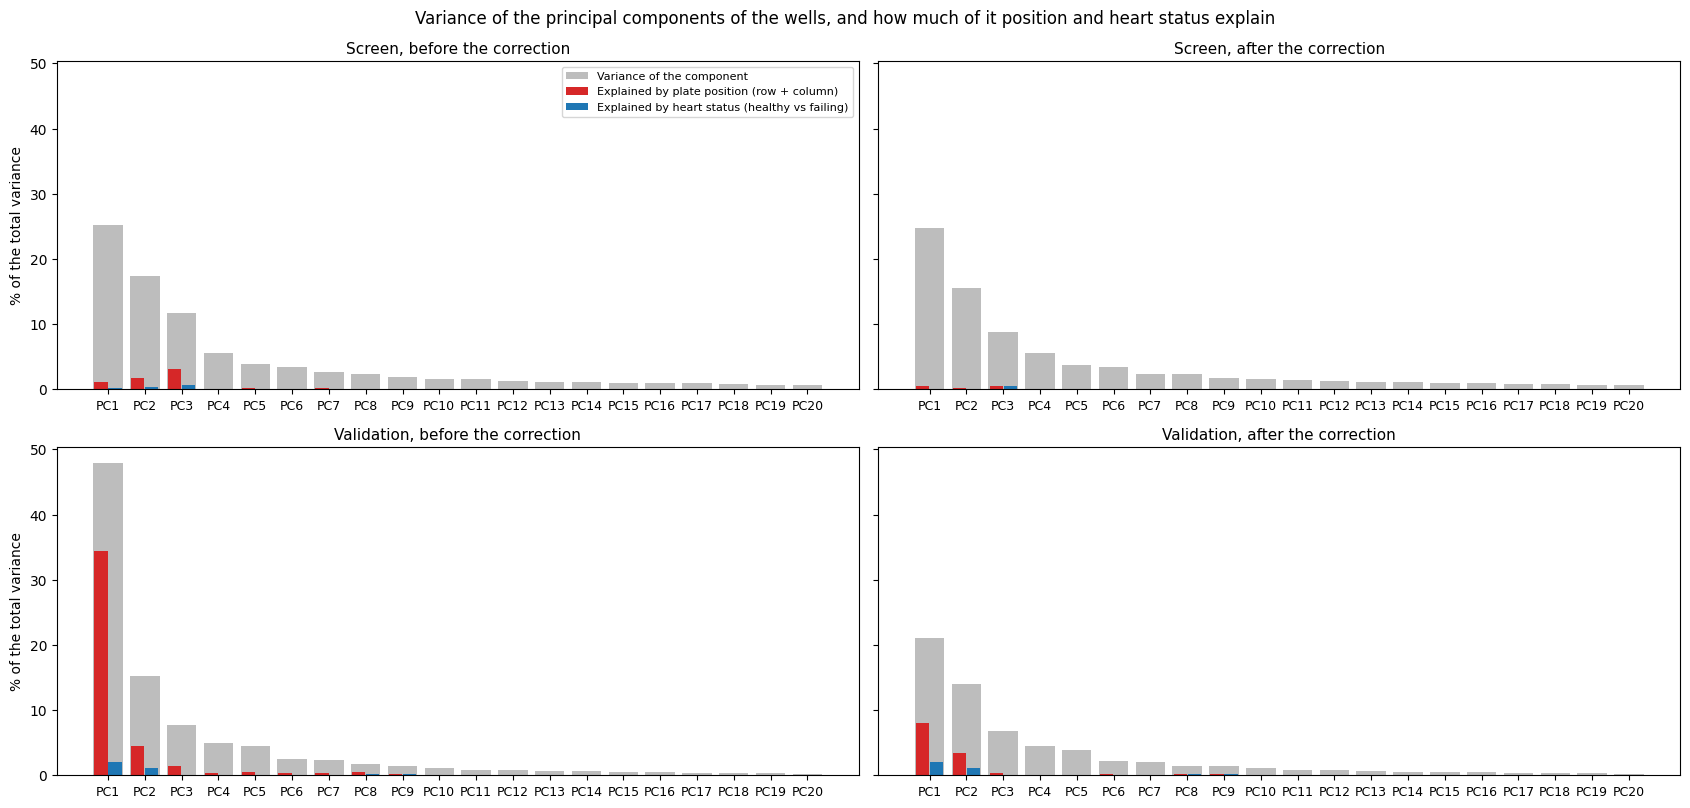

In [4]:
fig, axes = plt.subplots(len(datasets), 2, figsize=(17, 8.2), sharey=True)
for i, (name, table) in enumerate(partitions.items()):
    for j, stage in enumerate(("before", "after")):
        ax = axes[i, j]
        subset = table[table["stage"] == stage]
        x = np.arange(len(subset))
        ax.bar(x, subset["variance_pct_of_total"], width=0.8, color=colors["total"], label="Variance of the component")
        ax.bar(x - 0.19, subset["position_pct_of_total"], width=0.36, color=colors["position"], label="Explained by plate position (row + column)")
        ax.bar(x + 0.19, subset["status_pct_of_total"], width=0.36, color=colors["status"], label="Explained by heart status (healthy vs failing)")
        ax.set_xticks(x)
        ax.set_xticklabels(subset["component"], fontsize=9)
        ax.set_title(f"{name}, {'before' if stage == 'before' else 'after'} the correction", fontsize=11)
        if j == 0:
            ax.set_ylabel("% of the total variance")
axes[0, 0].legend(fontsize=8, loc="upper right")
fig.suptitle("Variance of the principal components of the wells, and how much of it position and heart status explain", fontsize=12)
fig.tight_layout()
fig.savefig(figure_dir / "scree_position_and_heart_status.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Survival of the healthy against failing difference

For every plate, the length of the difference between the mean healthy DMSO profile and the mean failing DMSO profile (over all features, in standard deviations of a single cell), before and after the correction.
On the screen, the healthy controls are in row B and the failing controls in row E on every platemap, so the correction shifts the two controls differently.
On the validation plates both cell types sit in every row, at the same positions on every plate, so the tilt shifts the two controls alike and leaves their difference as it is.
The part of the difference that survives is what position does not explain.

In [5]:
def healthy_failing_difference(medians, fit, healthy_label):
    """Length of the healthy minus failing DMSO difference of every plate, before and after the correction."""
    features = list(fit["features"])
    raw = medians[features].to_numpy(float)
    corrected = pce.correct_well_medians(medians, fit)[features].to_numpy(float)
    is_dmso = (medians["treatment"] == "DMSO").to_numpy()
    healthy = is_dmso & (medians["cell_type"] == healthy_label).to_numpy()
    failing = is_dmso & (medians["cell_type"] == "failing").to_numpy()
    records = []
    for plate in sorted(medians["plate"].unique()):
        in_plate = (medians["plate"] == plate).to_numpy()
        h, f = in_plate & healthy, in_plate & failing
        raw_difference = raw[h].mean(0) - raw[f].mean(0)
        corrected_difference = corrected[h].mean(0) - corrected[f].mean(0)
        records.append(
            {
                "plate": plate,
                "platemap": int(medians.loc[in_plate, "platemap"].iloc[0]),
                "raw": np.linalg.norm(raw_difference),
                "corrected": np.linalg.norm(corrected_difference),
            }
        )
    table = pd.DataFrame(records)
    table["share_that_survives"] = table["corrected"] / table["raw"]
    return table


survival = {name: healthy_failing_difference(data["medians"], data["fit"], data["healthy"]) for name, data in datasets.items()}
pd.concat(survival, names=["dataset"]).reset_index(level=0).to_csv(results_dir / "healthy_failing_survival.csv", index=False)
print(pd.DataFrame({name: table[["raw", "corrected", "share_that_survives"]].median() for name, table in survival.items()}).round(2).to_string())

                     Screen  Validation
raw                   19.52       12.97
corrected             18.47       12.97
share_that_survives    0.84        1.00


/var/folders/02/q30k_4wn2dqbz5pj_vvc8xn40000gp/T/ipykernel_9543/3015388611.py:13: RuntimeWarning: Mean of empty slice
  raw_difference = raw[h].mean(0) - raw[f].mean(0)
/Users/waygr/repos/wayscience/cardiac_fibrosis_rescue_screen_profiling/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/var/folders/02/q30k_4wn2dqbz5pj_vvc8xn40000gp/T/ipykernel_9543/3015388611.py:14: RuntimeWarning: Mean of empty slice
  corrected_difference = corrected[h].mean(0) - corrected[f].mean(0)


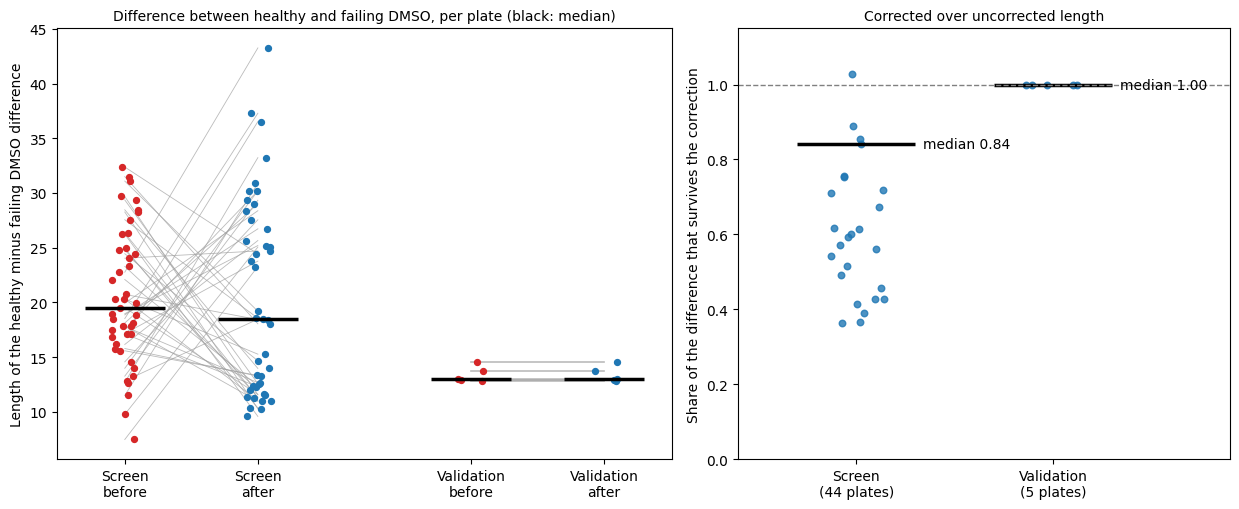

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
rng = np.random.default_rng(seed)
positions = {"Screen": (0, 1), "Validation": (2.6, 3.6)}
for name, table in survival.items():
    left, right = positions[name]
    for _, plate in table.iterrows():
        ax.plot([left, right], [plate["raw"], plate["corrected"]], color="#9e9e9e", lw=0.6 if name == "Screen" else 1.2, alpha=0.7)
    ax.scatter(np.full(len(table), left) + rng.uniform(-0.1, 0.1, len(table)), table["raw"], s=18, color=colors["position"], zorder=3)
    ax.scatter(np.full(len(table), right) + rng.uniform(-0.1, 0.1, len(table)), table["corrected"], s=18, color=colors["status"], zorder=3)
    ax.hlines([table["raw"].median(), table["corrected"].median()], [left - 0.3, right - 0.3], [left + 0.3, right + 0.3], color="black", lw=2.5, zorder=4)
ax.set_xticks([0, 1, 2.6, 3.6])
ax.set_xticklabels(["Screen\nbefore", "Screen\nafter", "Validation\nbefore", "Validation\nafter"])
ax.set_ylabel("Length of the healthy minus failing DMSO difference")
ax.set_title("Difference between healthy and failing DMSO, per plate (black: median)", fontsize=10)
ax = axes[1]
for k, (name, table) in enumerate(survival.items()):
    ax.scatter(np.full(len(table), k) + rng.uniform(-0.15, 0.15, len(table)), table["share_that_survives"], s=22, color=colors["status"], alpha=0.8)
    median = table["share_that_survives"].median()
    ax.hlines(median, k - 0.3, k + 0.3, color="black", lw=2.5)
    ax.text(k + 0.34, median, f"median {median:.2f}", va="center", fontsize=10)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlim(-0.6, 1.9)
ax.set_ylim(0, 1.15)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Screen\n(44 plates)", "Validation\n(5 plates)"])
ax.set_ylabel("Share of the difference that survives the correction")
ax.set_title("Corrected over uncorrected length", fontsize=10)
fig.tight_layout()
fig.savefig(figure_dir / "healthy_failing_survival.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. What the tilt estimates on the validation plates, and how well

**The model.** The correction subtracts, from every feature, a position effect that is the sum of one effect for the row of the well and one effect for its column (the tilt).
The model of a feature that the fit solves has one effect for each group (a compound, or the DMSO of one cell type), five row effects (rows C to G against row B), and ten column effects, with a tiny ridge penalty instead of a reference column (they are reported against column 2).
The groups sit in blocks of columns, so three column offsets (failing, healthy, compound columns) cannot be told from the group effects; the ridge sets them to zero.
It is fit on the wells of the 15 compounds and of the two kinds of DMSO, separately for each of the 2,453 features, with the replicate plates averaged.
The group effects are there so that what a compound or a cell type does is not counted as position.
The DMSO of each cell type is at 18 positions on every plate, three in each row.
A compound is at 8 positions on a single plate (columns 5 to 8, in all six rows), so a compound adds position information only through the other compounds and the DMSO wells that share its rows and columns.

**How well each term is determined.** We refit the tilt five times, each time without one plate, and measure how much every row and column term changes (the jackknife standard error).
A term whose estimate changes as much as its own size is not determined by these plates.

In [7]:
wells = datasets["Validation"]["medians"]
features = list(datasets["Validation"]["fit"]["features"])
n_row_terms = pcu.N_ROW_TERMS


def position_terms(fit):
    """Row effects against row B and column effects against column 2, one vector over features per term."""
    coefficients = fit["coef"]
    rows = coefficients[1:n_row_terms] - coefficients[0]
    cols = coefficients[n_row_terms:]
    return np.vstack([rows, cols])


term_names = [f"Row {row} vs B" for row in "CDEFG"] + [f"Column {c} vs 2" for c in range(3, 12)]
full_terms = position_terms(vpu.fit_compound_adjusted_tilt(wells, features, min_cells, include_controls=True))
plates = sorted(wells["plate"].unique())
leave_one_out = np.stack(
    [
        position_terms(
            vpu.fit_compound_adjusted_tilt(wells[wells["plate"] != plate], features, min_cells, include_controls=True)
        )
        for plate in plates
    ]
)
n = len(plates)
jackknife_se = np.sqrt((n - 1) / n * ((leave_one_out - leave_one_out.mean(axis=0)) ** 2).sum(axis=0))
term_table = pd.DataFrame(
    {
        "term": term_names,
        "size": np.linalg.norm(full_terms, axis=1),
        "uncertainty": np.linalg.norm(jackknife_se, axis=1),
    }
)
term_table["size_over_uncertainty"] = term_table["size"] / term_table["uncertainty"]
term_table.to_csv(results_dir / "tilt_term_uncertainty.csv", index=False)
term_table.round(2)

,term,size,uncertainty,size_over_uncertainty
0,Row C vs B,12.05,2.34,5.15
1,Row D vs B,20.58,3.01,6.83
2,Row E vs B,23.28,3.37,6.92
3,Row F vs B,28.45,4.16,6.84
4,Row G vs B,27.20,5.01,5.42
5,Column 3 vs 2,2.83,2.15,1.32
6,Column 4 vs 2,3.94,2.33,1.69
7,Column 5 vs 2,2.48,2.04,1.22
8,Column 6 vs 2,2.79,2.72,1.03
9,Column 7 vs 2,4.42,2.67,1.66


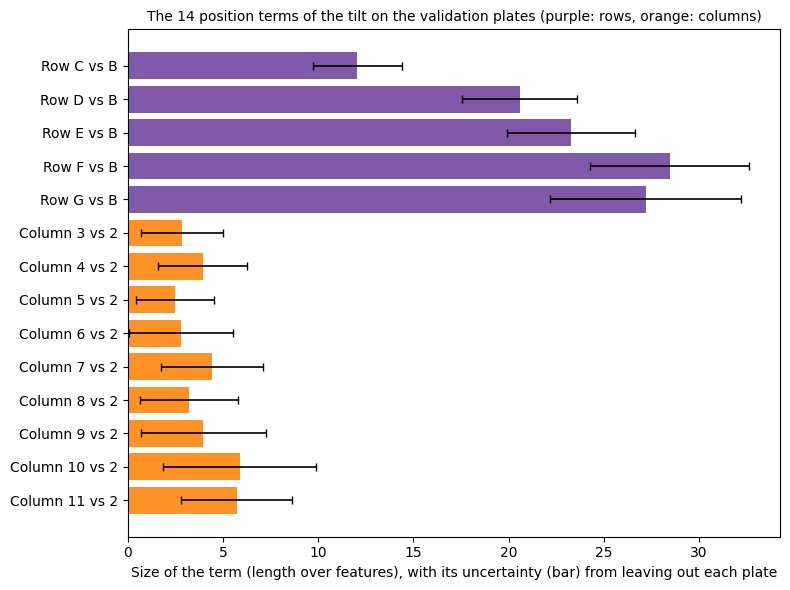

In [8]:
fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(term_table))[::-1]
term_colors = ["#6a3d9a" if name.startswith("Row") else "#ff7f00" for name in term_table["term"]]
ax.barh(y, term_table["size"], color=term_colors, alpha=0.85)
ax.errorbar(term_table["size"], y, xerr=term_table["uncertainty"], fmt="none", ecolor="black", capsize=3, lw=1.2)
ax.set_yticks(y)
ax.set_yticklabels(term_table["term"])
ax.set_xlabel("Size of the term (length over features), with its uncertainty (bar) from leaving out each plate")
ax.set_title("The 14 position terms of the tilt on the validation plates (purple: rows, orange: columns)", fontsize=10)
fig.tight_layout()
fig.savefig(figure_dir / "tilt_terms_and_uncertainty.png", dpi=150, bbox_inches="tight")
plt.show()

**The position variation of every feature.**
Each point is one feature: the share of the variation within the DMSO groups that is position (see `5.quantify_position_effect.ipynb`), before the correction (horizontal) and after it (vertical).
A feature on the diagonal is not changed by the correction, and a feature near zero has no position effect left.
On the left, the tilt is fit on all plates, so it fits the wells that it is judged on.
On the right, the tilt was fit without the plate that is judged, which is the situation of a new plate.

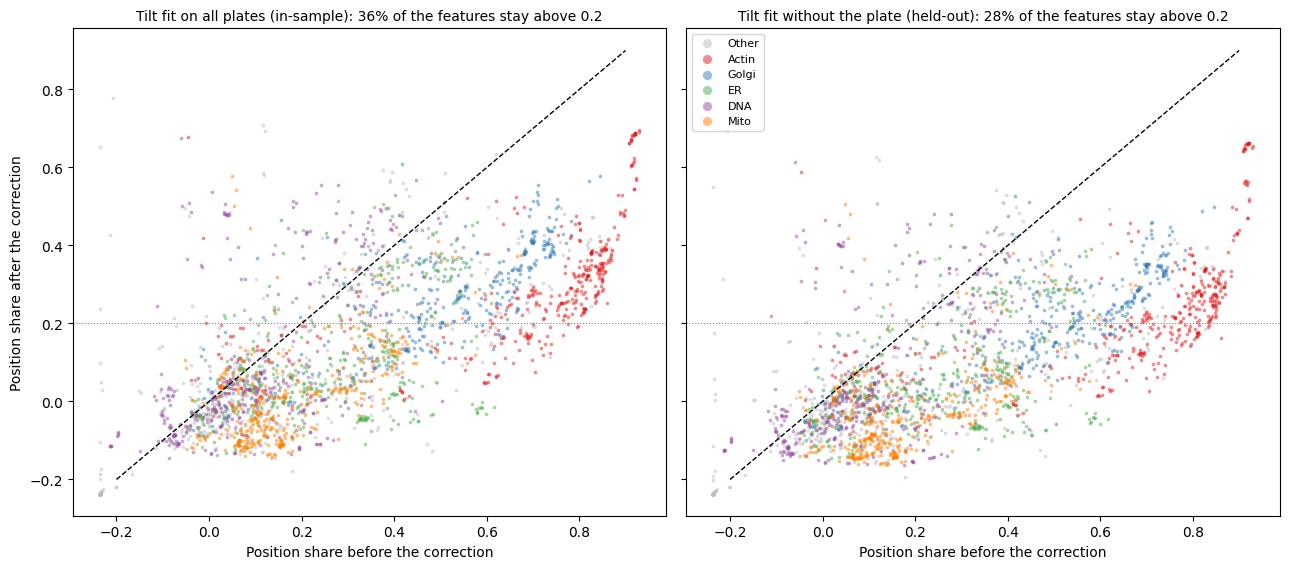

In [9]:
shares = pd.read_csv(results_dir / "position_variance_by_feature.csv").dropna(subset=["raw", "in_sample", "held_out"])
channel_colors = {"Actin": "#e41a1c", "Golgi": "#377eb8", "ER": "#4daf4a", "DNA": "#984ea3", "Mito": "#ff7f00"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharex=True, sharey=True)
for ax, column, title in (
    (axes[0], "in_sample", "Tilt fit on all plates (in-sample)"),
    (axes[1], "held_out", "Tilt fit without the plate (held-out)"),
):
    others = ~shares["channel"].isin(channel_colors)
    ax.scatter(shares.loc[others, "raw"], shares.loc[others, column], s=7, color="#bdbdbd", alpha=0.5, lw=0, label="Other")
    for channel, color in channel_colors.items():
        subset = shares[shares["channel"] == channel]
        ax.scatter(subset["raw"], subset[column], s=7, color=color, alpha=0.5, lw=0, label=channel)
    ax.plot([-0.2, 0.9], [-0.2, 0.9], color="black", lw=1, ls="--")
    ax.axhline(0.2, color="grey", lw=0.8, ls=":")
    share_left = (shares[column] > 0.2).mean()
    ax.set_title(f"{title}: {share_left:.0%} of the features stay above 0.2", fontsize=10)
    ax.set_xlabel("Position share before the correction")
axes[0].set_ylabel("Position share after the correction")
axes[1].legend(fontsize=8, markerscale=2.5, loc="upper left")
fig.tight_layout()
fig.savefig(figure_dir / "position_variance_before_vs_after.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Compound placement in the screen

The tilt of the screen, and its use in the rescue score, assume that compounds were placed on the plates independently of the position.
Each screen compound sits at one position of its platemap, so the assumption cannot be tested within a compound.
We test two things: whether the compound classes (pathways) differ by plate row, and whether the compound identifier (a running number) follows the order of the wells on a platemap.

In [10]:
frames = []
for path in sorted(platemap_dir.glob("*_with_pathways.csv")):
    frame = pd.read_csv(path)
    frame["platemap"] = int(path.name.split("Plate_")[1].split("_")[0])
    frames.append(frame)
platemaps = pd.concat(frames, ignore_index=True)
screen_compounds = platemaps[(platemaps["treatment"] != "DMSO") & platemaps["treatment"].notna()].copy()
screen_compounds["row_index"] = screen_compounds["well_position"].str[0].map({row: i for i, row in enumerate("BCDEFG")})
screen_compounds["column"] = screen_compounds["well_position"].str[1:].astype(int)
screen_compounds["reading_order"] = screen_compounds["row_index"] * 10 + screen_compounds["column"]
screen_compounds["compound_number"] = screen_compounds["treatment"].str.extract(r"(\d+)")[0].astype(float)

pathway_table = pd.crosstab(screen_compounds["Pathway"].fillna("none"), screen_compounds["well_position"].str[0])
chi2, p_pathway, dof, _ = chi2_contingency(pathway_table)
print(f"Pathway against plate row: chi-square p = {p_pathway:.2f} ({len(screen_compounds)} compounds, {pathway_table.shape[0]} pathways)")

placement = []
for platemap, group in screen_compounds.groupby("platemap"):
    result = spearmanr(group["compound_number"], group["reading_order"], nan_policy="omit")
    placement.append({"platemap": platemap, "n_compounds": len(group), "spearman_rho": result.statistic, "p_value": result.pvalue})
placement = pd.DataFrame(placement)
placement.to_csv(results_dir / "screen_compound_placement.csv", index=False)
print(placement.round(3).to_string(index=False))

Pathway against plate row: chi-square p = 0.62 (558 compounds, 24 pathways)
 platemap  n_compounds  spearman_rho  p_value
        1           52         0.076    0.594
        2           52         0.140    0.324
        3           52         0.133    0.348
        4           52         0.235    0.093
        5           52         0.540    0.000
        6           52         0.102    0.471
        7           52         0.489    0.000
        8           52         0.707    0.000
        9           52         0.045    0.749
       10           52         0.565    0.000
       11           38         0.212    0.262


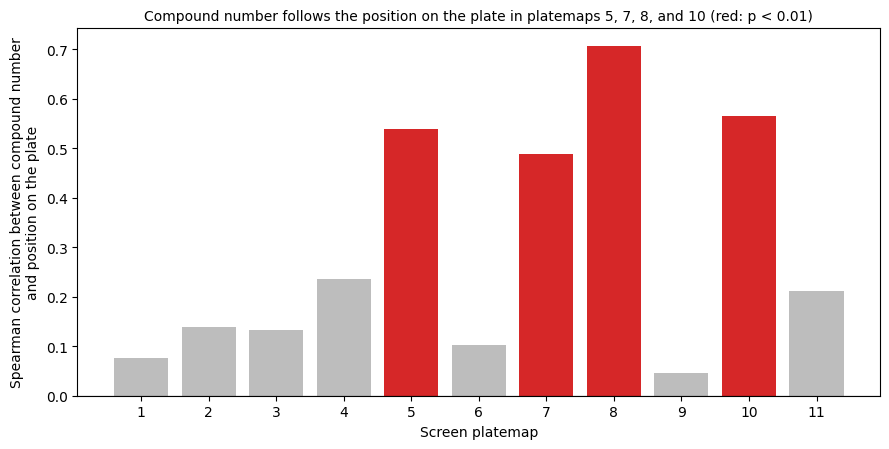

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6))
order = placement.sort_values("platemap")
bar_colors = [colors["position"] if p < 0.01 else "#bdbdbd" for p in order["p_value"]]
ax.bar(order["platemap"].astype(str), order["spearman_rho"], color=bar_colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Screen platemap")
ax.set_ylabel("Spearman correlation between compound number\nand position on the plate")
ax.set_title("Compound number follows the position on the plate in platemaps 5, 7, 8, and 10 (red: p < 0.01)", fontsize=10)
fig.tight_layout()
fig.savefig(figure_dir / "screen_compound_placement.png", dpi=150, bbox_inches="tight")
plt.show()